### Training the ridge classifier model


### Import the required libraries

In [ ]:
import pandas as pd                     # For reading CSV files and handling tabular data
import numpy as np                      # For numerical operations on arrays
import matplotlib.pyplot as plt         # For plotting graphs
import seaborn as sns                   # For plotting confusion matrix heatmap

from sklearn.model_selection import train_test_split   # For splitting dataset into train/test
from sklearn.linear_model import RidgeClassifier       # Ridge Classifier model
from sklearn.preprocessing import LabelEncoder         # For converting text labels → numeric
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report  # Evaluation metrics
import joblib                        # For saving trained model and encoder
from google.colab import drive        # to access required dataset from google drive

## mount the google drive to access required dataset

In [ ]:

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Load dataset from csv file

In [ ]:
# Load dataset from csv file without a header
data = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/major_project/landmarks.csv", header=None)

In [ ]:
print("One example row for each label (showing relevant columns):")

# Find the first row for 'appropriate'
appropriate_row = data[data.iloc[:, -1] == 'appropriate'].head(1)

# Find the first row for 'cheating'
cheating_row = data[data.iloc[:, -1] == 'cheating'].head(1)

# Find the first row for 'defensive'
defensive_row = data[data.iloc[:, -1] == 'defensive'].head(1)

# Display the found rows
display(appropriate_row)
display(cheating_row)
display(defensive_row)

One example row for each label (showing relevant columns):


,0,1,2,3,4,5,6,7,8,9,...,2163,2164,2165,2166,2167,2168,2169,2170,2171,2172
0,0.453955,0.353385,-0.029634,1.0,0.45465,0.309792,-0.045117,1.0,0.454565,0.326494,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,appropriate


,0,1,2,3,4,5,6,7,8,9,...,2163,2164,2165,2166,2167,2168,2169,2170,2171,2172
2000,0.503039,0.27306,-0.031538,1.0,0.504726,0.227077,-0.043098,1.0,0.503243,0.244722,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,cheating


,0,1,2,3,4,5,6,7,8,9,...,2163,2164,2165,2166,2167,2168,2169,2170,2171,2172
4000,0.449203,0.424144,-0.010829,1.0,0.447553,0.395404,-0.034673,1.0,0.448345,0.401397,...,1.0,0.622687,0.789288,-0.0371,1.0,0.634717,0.77418,-0.037604,1.0,defensive


# Separate features (X) and labels (y_raw)

In [ ]:
# Separate features (X) and labels (y_raw)
# Assuming the last column contains the labels and all others are features
X = data.iloc[:, :-1].values   # Select all columns except the last one as features
y_raw = data.iloc[:, -1].values # Select the last column as raw text labels

In [ ]:
print("Dataset shape:", data.shape)     # Print number of rows and columns
print("Example labels:", np.unique(y_raw))  # Show unique label names in dataset

Dataset shape: (6000, 2173)
Example labels: ['appropriate' 'cheating' 'defensive']


## Encode labels
# Initialize LabelEncoder to convert text labels to numeric values

In [ ]:
# Initialize LabelEncoder to convert text labels to numeric values
encoder = LabelEncoder()

# Fit encoder on raw labels and transform them into integers
y = encoder.fit_transform(y_raw)

# Save encoder to use later (so we can decode predictions back to text during inference)

In [ ]:
joblib.dump(encoder, "label_encoder.pkl")

['label_encoder.pkl']

  # Show mapping of numeric values → class names

In [ ]:
print("Classes encoded as:", encoder.classes_)

Classes encoded as: ['appropriate' 'cheating' 'defensive']


# Train/Test Split



#### Split dataset into 70% training and 30% testing
#### stratify=y ensures class distribution is balanced in both sets

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

In [ ]:
print("Training samples:", X_train.shape[0])   # Print number of training samples
print("Testing samples:", X_test.shape[0])     # Print number of testing sample

Training samples: 4200
Testing samples: 1800


#  Train Ridge Classifier

### Train the model using training data

In [ ]:
ridge = RidgeClassifier(alpha=1.0) # Initialize Ridge Classifier model with alpha = 1.0 (regularization strength)
ridge.fit(X_train, y_train)

RidgeClassifier()

In [ ]:
# Save the trained model to file
joblib.dump(ridge, "ridge_model.pkl")

print("Model trained and saved as ridge_model.pkl")

Model trained and saved as ridge_model.pkl


In [ ]:
# CELL 6: Evaluate Model

### Predict labels for the test dataset
y_pred_test = ridge.predict(X_test)

### Compute accuracy score on test data
acc_test = accuracy_score(y_test, y_pred_test)
print("Accuracy on Test Data:", acc_test)

### Predict labels for the training dataset
y_pred_train = ridge.predict(X_train)

### Compute accuracy score on the training dataset
acc_train = accuracy_score(y_train, y_pred_train)
print("Accuracy on Training Data:", acc_train)


### Generate classification report (precision, recall, F1-score for each class)
report_text = classification_report(y_test, y_pred_test, target_names=encoder.classes_)
print("\nClassification Report on Test Data:\n", report_text)

### Save classification report into a text file for record
with open("classification_report.txt", "w") as f:
    f.write(report_text)

Accuracy on Test Data: 0.9766666666666667
Accuracy on Training Data: 0.9638095238095238

Classification Report on Test Data:
               precision    recall  f1-score   support

 appropriate       0.95      0.99      0.97       600
    cheating       0.99      0.94      0.96       600
   defensive       0.99      1.00      0.99       600

    accuracy                           0.98      1800
   macro avg       0.98      0.98      0.98      1800
weighted avg       0.98      0.98      0.98      1800



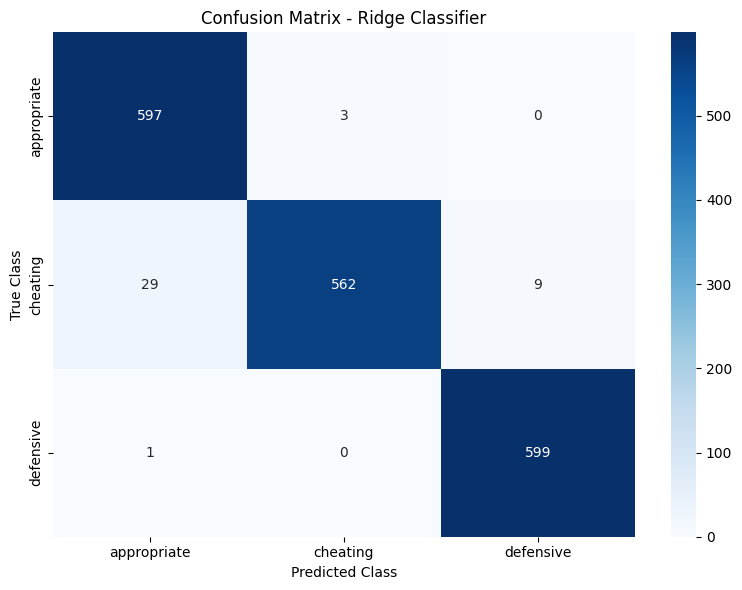

In [ ]:
# Confusion Matrix

## Compute confusion matrix (rows = true classes, columns = predicted classes)
cm = confusion_matrix(y_test, y_pred_test)
labels = encoder.classes_   # Use original class names for axes

## Plot confusion matrix as heatmap
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)

plt.xlabel("Predicted Class")   # X-axis label
plt.ylabel("True Class")        # Y-axis label
plt.title("Confusion Matrix - Ridge Classifier")
plt.tight_layout()
plt.savefig("confusion_matrix.png")   # Save confusion matrix as PNG file
plt.show()

# Task
Extract feature vectors for 'appropriate', 'cheating', and 'defensive' labels from the dataset and save them into separate CSV files named 'appropriate_features.csv', 'cheating_features.csv', and 'defensive_features.csv' respectively, then confirm their creation.

## Extract Features for 'appropriate' Label

### Subtask:
Filter the original dataset to include only rows where the label is 'appropriate', and then extract the feature columns. Save these features to a CSV file named 'appropriate_features.csv'.


**Reasoning**:
To extract features for the 'appropriate' label, I need to filter the original dataframe `data` to include only rows where the last column (label) is 'appropriate', then select all columns except the last one as features, and finally save these features to a CSV file.



In [ ]:
appropriate_data = data[data.iloc[:, -1] == 'appropriate']
appropriate_features = appropriate_data.iloc[:, :-1]
appropriate_features.to_csv('appropriate_features.csv', index=False)
print("Features for 'appropriate' label extracted and saved to 'appropriate_features.csv'.")

Features for 'appropriate' label extracted and saved to 'appropriate_features.csv'.


## Extract Features for 'cheating' Label

### Subtask:
Filter the original dataset to include only rows where the label is 'cheating', and then extract the feature columns. Save these features to a CSV file named 'cheating_features.csv'.

**Reasoning**:
To extract features for the 'cheating' label, I need to filter the original dataframe `data` to include only rows where the last column (label) is 'cheating', then select all columns except the last one as features, and finally save these features to a CSV file.



In [ ]:
cheating_data = data[data.iloc[:, -1] == 'cheating']
cheating_features = cheating_data.iloc[:, :-1]
cheating_features.to_csv('cheating_features.csv', index=False)
print("Features for 'cheating' label extracted and saved to 'cheating_features.csv'.")

Features for 'cheating' label extracted and saved to 'cheating_features.csv'.


## Extract Features for 'defensive' Label

### Subtask:
Filter the original dataset to include only rows where the label is 'defensive', and then extract the feature columns. Save these features to a CSV file named 'defensive_features.csv'.

**Reasoning**:
To extract features for the 'defensive' label, I need to filter the original dataframe `data` to include only rows where the last column (label) is 'defensive', then select all columns except the last one as features, and finally save these features to a CSV file.



In [ ]:
defensive_data = data[data.iloc[:, -1] == 'defensive']
defensive_features = defensive_data.iloc[:, :-1]
defensive_features.to_csv('defensive_features.csv', index=False)
print("Features for 'defensive' label extracted and saved to 'defensive_features.csv'.")

Features for 'defensive' label extracted and saved to 'defensive_features.csv'.


## Final Task

### Subtask:
Confirm that the feature vectors for each label have been successfully saved into their respective CSV files.


## Summary:

### Data Analysis Key Findings
*   Feature vectors for the 'appropriate' label were successfully extracted and saved to a CSV file named `appropriate_features.csv`.
*   Feature vectors for the 'cheating' label were successfully extracted and saved to a CSV file named `cheating_features.csv`.
*   Feature vectors for the 'defensive' label were successfully extracted and saved to a CSV file named `defensive_features.csv`.
*   All feature extractions and saving operations were confirmed via print statements, indicating successful completion.

### Insights or Next Steps
*   The generated CSV files can now be used as input for training separate machine learning models tailored to each specific behavior or for further specialized analysis.
*   Consider implementing a function or loop to automate the extraction and saving process for multiple labels, making it more scalable and less repetitive for a larger number of categories.
